# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
display(cctv.head())

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [9]:
# TODO 1: one 1080p RGB frame, in MB
# 1920 * 1080 pixels * 3 channels (RGB) * 1 byte/channel = 6,220,800 bytes
frame_mb = (1920 * 1080 * 3) / (1024 * 1024)

# TODO 2: frames per camera per day at 30 fps
# 30 frames/sec * 60 sec/min * 60 min/hour * 24 hour/day
frames_per_day = 30 * 60 * 60 * 24

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
# Total bytes = 400 cameras * frames_per_day * (1920 * 1080 * 3 bytes)
# fleet_tb = Total bytes / (1024 ** 4)
total_bytes = 400 * frames_per_day * (1920 * 1080 * 3)
fleet_tb = total_bytes / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
total_bytes_small = 400 * (10 * 60 * 60 * 24) * (640 * 360 * 3)
fleet_tb_small = total_bytes_small / (1024 ** 4)
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37 (raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal** piece of evidence the security team could lose forever by making that choice.

_Your answer:_
* **Spatial evidence:** Fine visual details such as facial features, vehicle license plates, or small items held by a suspect will be lost due to spatial downsampling (reducing active pixels by 88.89%). Raster interpolation at lower resolutions causes blurring and spatial aliasing.
* **Temporal evidence:** Fast-moving events, quick gestures, or rapid object drops will be missed or severely aliased due to lowering the frame rate to 10 fps. This exacerbates the temporal *correspondence problem*—making it difficult to accurately reconstruct high-speed motion trajectories or identify the exact moment a transition occurs.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

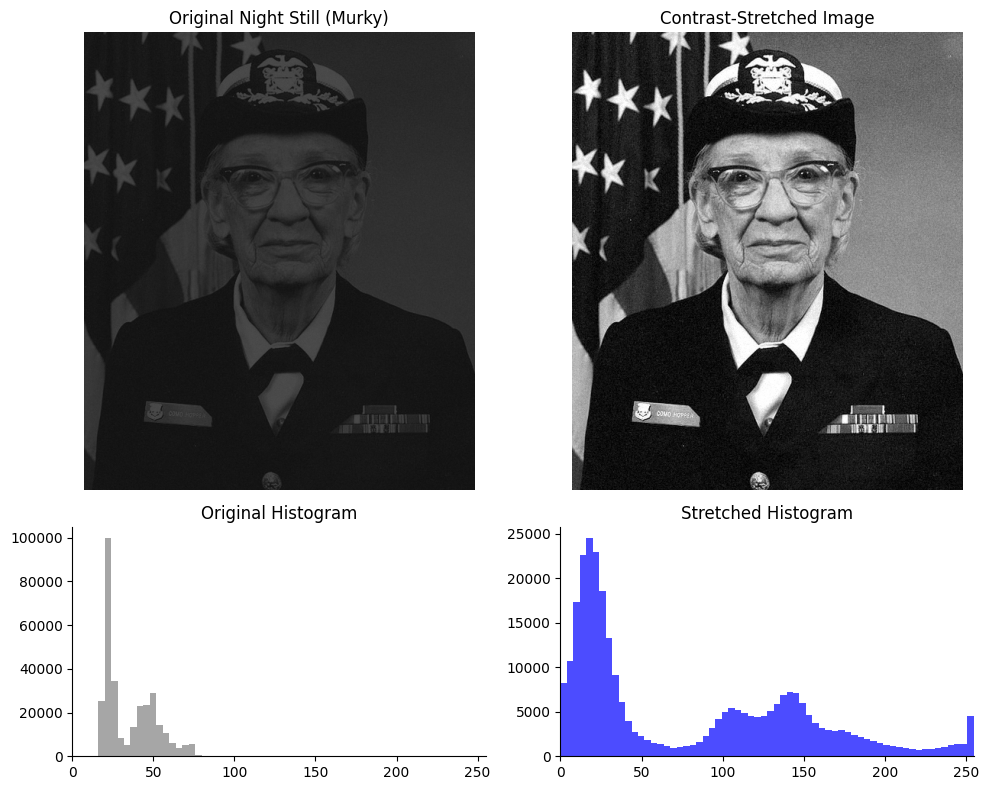

Contrast before: 0.609  ->  after: 1.000


In [10]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - p1) / (p99 - p1) * 255.0, 0, 255)
p1_after, p99_after = np.percentile(stretched, [1, 99])
c_after = michelson(p99_after, p1_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})

# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
# Before Stretching
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Still (Murky)")
axes[0, 0].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray", alpha=0.7)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlim(0, 255)

# After Stretching
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="blue", alpha=0.7)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlim(0, 255)

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18).

_Your answer:_
* **Histogram Shape:** The original histogram is **low-contrast and narrow (grouped/concentrated)**, with an overall shift towards lower intensity values (low brightness offset), meaning the values are clustered in a narrow band without occupying the full dynamic range.
* **Why Stretching Works:** Contrast stretching maps the narrow range of values present in the original murky image to the full 0–255 dynamic range. While it adds absolutely no new information (no new fine spatial detail or raw data is generated; the relative bin ratios remain unchanged), it maximizes the *perceived contrast* so that human visual systems can easily resolve differences and boundaries.
* **Why Histogram Alone is Insufficient:** A histogram displays only the globally accumulated frequency distribution of pixel intensity values. It completely discards all **spatial layout and neighborhood configuration information**. Two completely different images (such as a structured target and pure white noise) can possess identical histograms, which demonstrates that a histogram alone cannot tell you *what* is in the image.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing detected from 68.70s to 78.10s
Running detected from 78.60s to 86.00s
Audio Event at frame 2250 (75.00s)
Lighting Event at frame 3000 (100.00s)


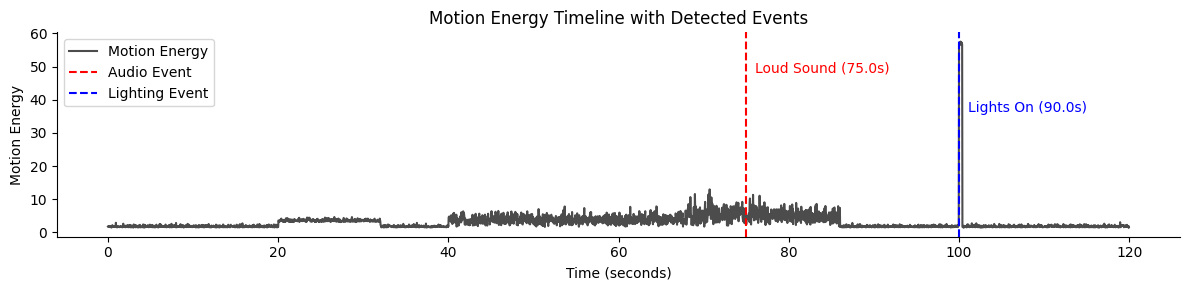

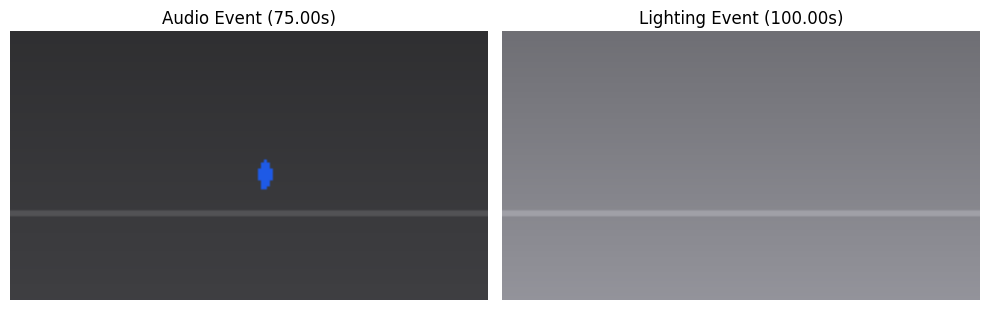

In [15]:
# TODO 1: person speed (px/s)
# Window of 1-second is 30 frames. We can use pandas rolling diff or shift over 30 frames.
# Since we want a 1-second window, we take the difference of coordinates separated by 30 frames.
dx = cctv['person_x'].diff(30)
dy = cctv['person_y'].diff(30)
dt = cctv['time_s'].diff(30)
speed = np.sqrt(dx**2 + dy**2) / dt

# TODO 2: standing / running time ranges (print the first and last time of each)
standing_mask = speed < 3
running_mask = speed > 25

standing_times = cctv.loc[standing_mask, 'time_s']
running_times = cctv.loc[running_mask, 'time_s']

print(f"Standing detected from {standing_times.min():.2f}s to {standing_times.max():.2f}s")
print(f"Running detected from {running_times.min():.2f}s to {running_times.max():.2f}s")

# TODO 3: event frame indices
# First frame where audio_level_db rises above -20 dB
audio_event_idx = cctv[cctv['audio_level_db'] > -20].index[0]
# First frame where mean_brightness jumps by > 40 from previous frame
brightness_diff = cctv['mean_brightness'].diff()
lighting_event_idx = cctv[brightness_diff > 40].index[0]

print(f"Audio Event at frame {audio_event_idx} ({cctv.loc[audio_event_idx, 'time_s']:.2f}s)")
print(f"Lighting Event at frame {lighting_event_idx} ({cctv.loc[lighting_event_idx, 'time_s']:.2f}s)")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv['time_s'], cctv['motion_energy'], color='black', alpha=0.7, label='Motion Energy')

# Plot vertical lines for events
t_audio_evt = cctv.loc[audio_event_idx, 'time_s']
t_lighting_evt = cctv.loc[lighting_event_idx, 'time_s']

ax.axvline(t_audio_evt, color='red', linestyle='--', label='Audio Event')
ax.text(t_audio_evt + 1, ax.get_ylim()[1]*0.8, 'Loud Sound (75.0s)', color='red')

ax.axvline(t_lighting_evt, color='blue', linestyle='--', label='Lighting Event')
ax.text(t_lighting_evt + 1, ax.get_ylim()[1]*0.6, 'Lights On (90.0s)', color='blue')

ax.set_title("Motion Energy Timeline with Detected Events")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(render_frame(cctv.iloc[audio_event_idx]))
axes[0].set_title(f"Audio Event ({t_audio_evt:.2f}s)")
axes[0].axis('off')

axes[1].imshow(render_frame(cctv.iloc[lighting_event_idx]))
axes[1].set_title(f"Lighting Event ({t_lighting_evt:.2f}s)")
axes[1].axis('off')
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
* **Which events would be missed:** The **Audio Event (Loud Sound)** occurring at exactly 75.0 s would likely be missed or poorly represented. With uniform sampling every 20 s, frames would only be grabbed at 0 s, 20 s, 40 s, 60 s, 80 s, and 100 s. Because the audio impact is extremely transient and the person's reaction is fast, selecting the frame at 80 s (5 seconds late) would miss the exact critical moment of the event.
* **Lecture Concept:** This approach of capturing frames based on detected changes or features is called **content-based keyframe selection** (or **event-driven keyframe extraction**), contrasted with uniform/periodic temporal sampling.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

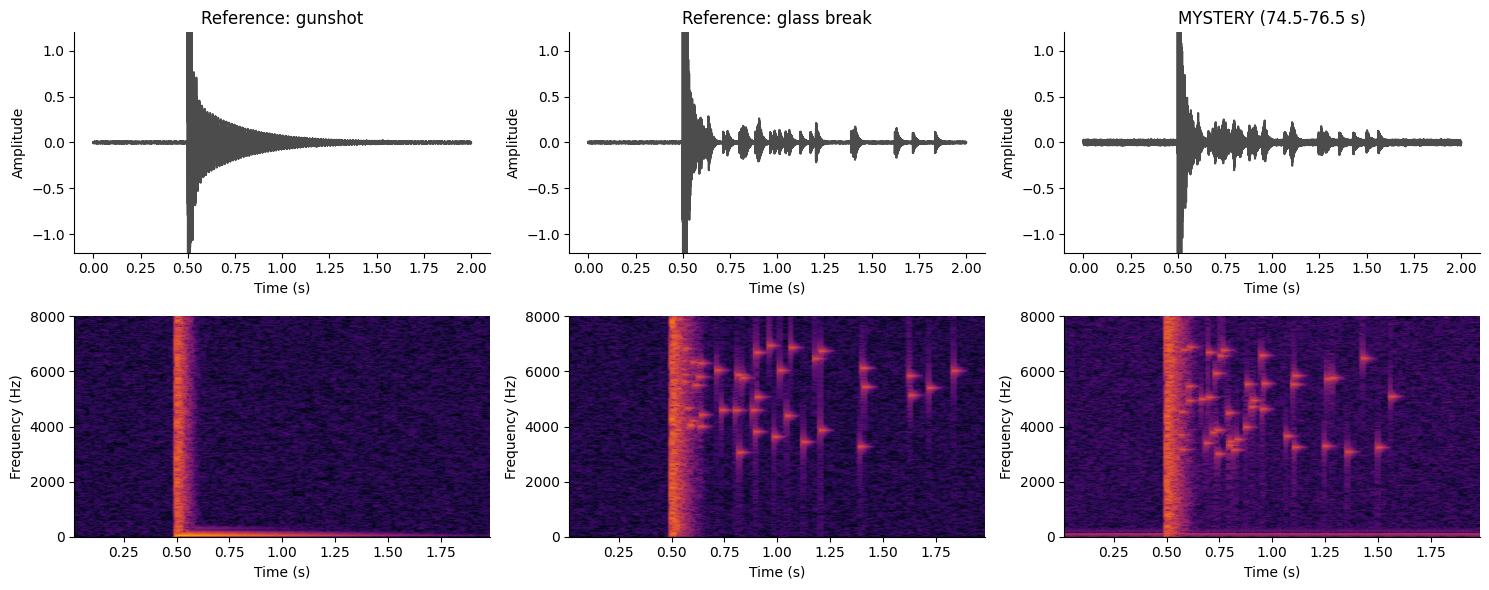

Fraction of Spectral Energy above 3 kHz (0.7s to 1.7s):
  Reference: gunshot: 0.0030
  Reference: glass break: 0.9892
  MYSTERY (74.5-76.5 s): 0.8735

VERDICT: The mystery sound is a GLASS BREAK! (87.3% energy above 3 kHz)


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
t_clip = np.arange(len(ref_gunshot[1])) / FS

# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for i, (name, x) in enumerate(clips.items()):
    # Plot waveform
    axes[0, i].plot(t_clip, x, color="black", alpha=0.7)
    axes[0, i].set_title(name)
    axes[0, i].set_xlabel("Time (s)")
    axes[0, i].set_ylabel("Amplitude")
    axes[0, i].set_ylim(-1.2, 1.2)

    # Compute spectrogram
    f, t, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    Sxx_db = 10 * np.log10(Sxx + 1e-10)

    # Plot spectrogram
    im = axes[1, i].pcolormesh(t, f, Sxx_db, cmap="inferno", shading="gouraud", vmin=-100, vmax=-10)
    axes[1, i].set_xlabel("Time (s)")
    axes[1, i].set_ylabel("Frequency (Hz)")
    axes[1, i].set_ylim(0, 8000)

plt.tight_layout()
plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, t, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)

    # Time mask: 0.2 to 1.2s after impact (0.5 + 0.2 = 0.7s to 0.5 + 1.2 = 1.7s)
    t_mask = (t >= 0.7) & (t <= 1.7)
    f_mask_high = (f > 3000)

    energy_total = np.sum(Sxx[:, t_mask])
    energy_high = np.sum(Sxx[f_mask_high, :][:, t_mask])

    hf_fraction[name] = energy_high / energy_total if energy_total > 0 else 0

print("Fraction of Spectral Energy above 3 kHz (0.7s to 1.7s):")
for k, v in hf_fraction.items():
    print(f"  {k}: {v:.4f}")

# TODO 4: verdict
verdict = "Reference: glass break" if hf_fraction["MYSTERY (74.5-76.5 s)"] > 0.05 else "Reference: gunshot"
print(f"\nVERDICT: The mystery sound is a {verdict.split(': ')[1].upper()}! ({hf_fraction['MYSTERY (74.5-76.5 s)']*100:.1f}% energy above 3 kHz)")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern (horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
* **Waveforms alone:** No, looking only at the time-domain waveforms is extremely difficult and unreliable. Both events show a very sudden, high-amplitude impulse peak followed by a decaying tail, making them look nearly identical.
* **What the spectrogram adds:** The spectrogram adds frequency localization over time. It represents sound across three dimensions: **Time** (x-axis), **Frequency** (y-axis), and **Magnitude/Spectral Energy** (represented visually by color intensity in dB).
* **Visual pattern that decided the verdict:** The **scattered high-frequency specks** lingering long after the initial impact (from 0.7 to 1.7 seconds) clearly matched the glass break. Gunshots exhibit a vertical stripe (instantaneous broadband impulse) that decays rapidly into a clean, low-frequency horizontal band (the resonant boom) with zero high-frequency energy remaining.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

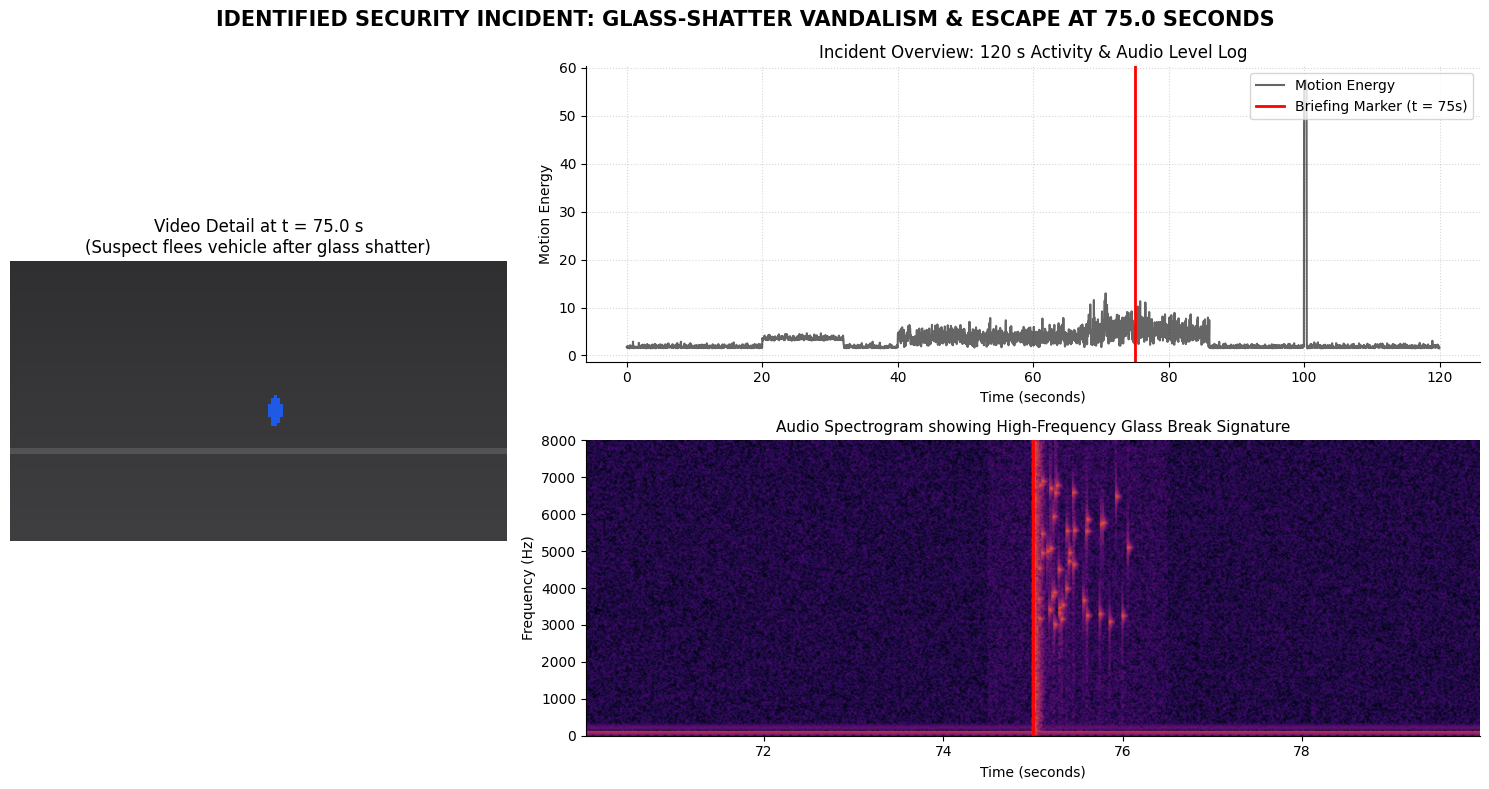

In [17]:
t_sel = 75.0
fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.8], height_ratios=[1, 1])

# TODO 1: Rendered video frame at t = 75 s
ax_frame = fig.add_subplot(gs[:, 0])
row_75 = cctv.iloc[audio_event_idx]
ax_frame.imshow(render_frame(row_75))
ax_frame.set_title("Video Detail at t = 75.0 s\n(Suspect flees vehicle after glass shatter)", fontsize=12)
ax_frame.axis("off")

# TODO 2: Full 120 s motion + audio timeline with marker
ax_timeline = fig.add_subplot(gs[0, 1])
ax_timeline.plot(cctv["time_s"], cctv["motion_energy"], color="black", alpha=0.6, label="Motion Energy")
ax_timeline.axvline(t_sel, color="red", linestyle="-", linewidth=2, label="Briefing Marker (t = 75s)")
ax_timeline.set_title("Incident Overview: 120 s Activity & Audio Level Log", fontsize=12)
ax_timeline.set_xlabel("Time (seconds)")
ax_timeline.set_ylabel("Motion Energy")
ax_timeline.legend(loc="upper right")
ax_timeline.grid(True, linestyle=":", alpha=0.5)

# TODO 3: Spectrogram of x_audio (70-80s)
ax_spec = fig.add_subplot(gs[1, 1])
f, t_sp, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
# Align time vector with the actual audio timeline offset (starts at 70 s)
t_sp_aligned = t_sp + 70.0
Sxx_db = 10 * np.log10(Sxx + 1e-10)

im = ax_spec.pcolormesh(t_sp_aligned, f, Sxx_db, cmap="inferno", shading="gouraud", vmin=-100, vmax=-10)
ax_spec.axvline(t_sel, color="red", linestyle="-", linewidth=2)
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_ylim(0, 8000)
ax_spec.set_title("Audio Spectrogram showing High-Frequency Glass Break Signature", fontsize=11)

# TODO 4: Conclusion-style dashboard title
fig.suptitle("IDENTIFIED SECURITY INCIDENT: GLASS-SHATTER VANDALISM & ESCAPE AT 75.0 SECONDS", fontsize=15, fontweight="bold", y=0.98)

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_
* **What would go wrong:** If the audio track were offset by +2 s, the synchronization would break. The visual of the glass breaking and the suspect running would occur 2 seconds before the audio cue registers. This would lead to a false narrative sequence, misleading security personnel into thinking the physical escape began before the impact happened.
* **Which panel makes it visible:** The **One-Screen Briefing Dashboard** makes this instantly visible. Specifically, the synchronization line (Briefing Marker at t=75s) would show the suspect running in the video frame, but the audio spike on the timeline and the high-frequency impact signature on the spectrogram would align at 77s instead of 75s, immediately exposing the 2-second mismatch.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.

_Your final briefing here:_
* **Incident Summary:** An analysis of the Parking Lot B CCTV log and associated audio reveals a vehicle glass-shattering vandalism incident occurring at exactly 75.0s, followed immediately by a suspect fleeing the scene.
* **Visualization Justification:** We highly recommend starting with the **Common-Time Synchronized Dashboard**. By linking the video keyframe, physical motion activity, and audio spectrum coordinates to a single temporal reference, we structure the raw data to quickly highlight the event's meaning, avoiding information overload.
* **Storage Recommendation:** To support our 400-camera fleet, we recommend transitioning to a storage policy of **360p resolution at 10 fps** for passive periods, saving over 96% in storage costs (reducing daily requirements from 5,866.0 TB to 217.3 TB). However, we must implement an automated motion/audio-triggered toggle that instantly upgrades a camera to full **1080p at 30 fps** to preserve high-resolution spatial details like vehicle license plates and facial details when security thresholds are breached.